# Step 1: Data Ingestion & Initial Understanding

The goal of this project is to develop a machine learning model that predicts whether a loan application will be **Approved** or **Rejected** based on applicant, financial, credit, and asset information.

In this step, we will download the dataset, load it into pandas, and perform an initial inspection of its structure and target variable.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
import kagglehub

# Download the latest version of the dataset
path = kagglehub.dataset_download(
    "architsharma01/loan-approval-prediction-dataset"
)

print("Path to dataset files:", path)

c:\Users\Minn Bern\MYPROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Minn Bern\.cache\kagglehub\datasets\architsharma01\loan-approval-prediction-dataset\versions\1


In [3]:
df_raw = pd.read_csv(
    os.path.join(path, "loan_approval_dataset.csv")
)

print("Dataset loaded successfully.")
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]:,}")

Dataset loaded successfully.
Rows    : 4,269
Columns : 13


In [4]:
# Column information
print(f"{'#':<5} {'Column':<30} {'Dtype':<15}")

for i, (col, dtype) in enumerate(df_raw.dtypes.items(), 1):
    print(f"{i:<5} {col:<30} {str(dtype):<15}")

#     Column                         Dtype          
1     loan_id                        int64          
2      no_of_dependents              int64          
3      education                     str            
4      self_employed                 str            
5      income_annum                  int64          
6      loan_amount                   int64          
7      loan_term                     int64          
8      cibil_score                   int64          
9      residential_assets_value      int64          
10     commercial_assets_value       int64          
11     luxury_assets_value           int64          
12     bank_asset_value              int64          
13     loan_status                   str            


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [6]:
df_raw.head(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


In [7]:
df_raw.sample(10, random_state=42)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
1703,1704,5,Graduate,No,5400000,19700000,20,423,6500000,10000000,15700000,7300000,Rejected
1173,1174,2,Graduate,No,5900000,14000000,8,599,4700000,9500000,17800000,6700000,Approved
308,309,3,Graduate,No,9600000,19900000,14,452,4200000,16200000,28500000,6600000,Rejected
1322,1323,2,Graduate,No,6200000,23400000,8,605,10000000,10800000,21800000,9200000,Approved
3271,3272,3,Not Graduate,Yes,5800000,14100000,12,738,11700000,4400000,15400000,8400000,Approved
3539,3540,4,Graduate,Yes,4700000,12500000,8,678,13700000,200000,9800000,7000000,Approved
1522,1523,4,Graduate,No,3400000,13500000,12,705,10000000,1100000,8300000,4900000,Approved
3399,3400,5,Not Graduate,Yes,5100000,13700000,14,527,12100000,8900000,19400000,4700000,Rejected
1402,1403,3,Graduate,Yes,3300000,8500000,12,586,7500000,5100000,7800000,3900000,Approved
1829,1830,1,Not Graduate,Yes,3000000,6000000,16,518,3800000,1700000,11600000,3900000,Rejected


### Identify the Target Variable

For this project, the target is `loan_status`, which indicates whether a loan application was **Approved** or **Rejected**.


In [8]:
# ── Clean column names ───────────────────────────────────
df_raw.columns = df_raw.columns.str.strip()

# Identify the target variable
TARGET = "loan_status"

print("Target variable:", TARGET)
print("\nTarget values:")
print(df_raw[TARGET].unique())

Target variable: loan_status

Target values:
<StringArray>
[' Approved', ' Rejected']
Length: 2, dtype: str


### Inspect Target Distribution

We examine how many applications belong to each loan-status class.

This is important because an imbalanced target can affect model training and evaluation. The class distribution will help us decide which evaluation metrics are appropriate later.


In [9]:
target_counts = df_raw[TARGET].value_counts()
target_percent = df_raw[TARGET].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percent.round(2)
})

display(target_summary)

,count,percentage
loan_status,,
Approved,2656,62.22
Rejected,1613,37.78


### Step 1 Summary

We have downloaded and loaded the loan approval dataset and established an initial understanding of its structure, variables, data types, and target variable.

The next step is **Data Quality Investigation**. We will check for missing values, duplicate records, inconsistent categorical values, invalid numerical values, unusual ranges, and other potential problems before making any cleaning decisions.


# Step 2: Data Quality Investigation

Before cleaning the dataset, we need to identify problems that could affect the analysis or machine learning models.

We will check for missing values, duplicates, inconsistent categories, invalid numerical values, unusual ranges, identifier issues, and target validity.

The results from these checks will determine what cleaning actions we take in Step 3.


In [10]:
# ── Missing values ────────────────────────────────────────
missing = df_raw.isnull().sum()

print(f"Total missing values: {missing.sum():,}")

if missing.sum() == 0:
    print("No missing values found.")
else:
    missing_summary = pd.DataFrame({
        "missing_count": missing,
        "missing_percent": (missing / len(df_raw) * 100).round(2)
    })

    display(missing_summary[missing_summary["missing_count"] > 0])

Total missing values: 0
No missing values found.


In [11]:
# ── Duplicate records ────────────────────────────────────
duplicate_count = df_raw.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


In [12]:
# ── Categorical values ───────────────────────────────────
categorical_columns = df_raw.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df_raw[col].value_counts(dropna=False))


education
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

self_employed
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

loan_status
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


C:\Users\Minn Bern\AppData\Local\Temp\ipykernel_17348\2048314894.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_raw.select_dtypes(include="object").columns


In [13]:
# ── Numerical summary ────────────────────────────────────
numeric_summary = df_raw.describe().T[
    ["min", "max", "mean", "50%"]
].rename(columns={"50%": "median"})

display(numeric_summary)

,min,max,mean,median
loan_id,1.00,"4,269.00","2,135.00","2,135.00"
no_of_dependents,0.00,5.00,2.50,3.00
income_annum,"200,000.00","9,900,000.00","5,059,123.92","5,100,000.00"
loan_amount,"300,000.00","39,500,000.00","15,133,450.46","14,500,000.00"
loan_term,2.00,20.00,10.90,10.00
cibil_score,300.00,900.00,599.94,600.00
residential_assets_value,"-100,000.00","29,100,000.00","7,472,616.54","5,600,000.00"
commercial_assets_value,0.00,"19,400,000.00","4,973,155.31","3,700,000.00"
luxury_assets_value,"300,000.00","39,200,000.00","15,126,305.93","14,600,000.00"
bank_asset_value,0.00,"14,700,000.00","4,976,692.43","4,600,000.00"


In [14]:
# ── Negative numerical values ────────────────────────────
numeric_columns = df_raw.select_dtypes(include=np.number).columns

negative_counts = (df_raw[numeric_columns] < 0).sum()

display(
    negative_counts[negative_counts > 0]
)

residential_assets_value    28
dtype: int64

### Interpretation

The check identified **28 negative values in `residential_assets_value`**. Since an asset value would normally be expected to be non-negative, these records require further investigation.

We will **not remove them at this stage**. In Step 3, we will inspect these records and decide whether the values should be corrected, treated as invalid, or handled another way. This prevents us from deleting potentially useful observations without understanding the issue.


In [15]:
# ── Loan ID uniqueness ───────────────────────────────────
print(f"Unique loan IDs : {df_raw['loan_id'].nunique():,}")
print(f"Total rows      : {len(df_raw):,}")
print(f"Duplicate IDs   : {df_raw['loan_id'].duplicated().sum():,}")

Unique loan IDs : 4,269
Total rows      : 4,269
Duplicate IDs   : 0


### Validate the Target Variable

The target should contain only the expected loan outcomes.

We verify that the dataset contains only `Approved` and `Rejected` values before moving to the cleaning stage.



In [16]:
# ── Target validation ────────────────────────────────────
valid_targets = {"Approved", "Rejected"}

actual_targets = set(df_raw[TARGET].dropna().unique())

print("Target values found:", actual_targets)
print("Unexpected values:", actual_targets - valid_targets)

Target values found: {' Rejected', ' Approved'}
Unexpected values: {' Rejected', ' Approved'}


### Interpretation

The target contains two expected classes: `Approved` and `Rejected`. However, the raw dataset contains leading whitespace in these values, causing the validation check to initially identify them as unexpected.

This is a **formatting inconsistency rather than a new target class**. The whitespace was normalized during the initial inspection, so the target can be handled consistently during cleaning and modeling.

No invalid target category was identified.


### Step 2 Summary

The data-quality investigation identifies issues that need to be addressed before modeling.

We have checked:

* Missing values
* Duplicate records
* Categorical consistency
* Numerical ranges
* Negative or suspicious values
* Loan identifier uniqueness
* Target validity

The findings from these checks will determine the cleaning operations performed in **Step 3: Data Cleaning**.


### Step 3: Data Cleaning

Now that the data-quality issues have been identified, we can clean the dataset before performing exploratory analysis and modeling.

The cleaning process will:

* Work on a copy of the raw dataset.
* Standardize column names and categorical text.
* Remove duplicate records if any exist.
* Validate the target variable.
* Investigate and handle the negative residential asset values.
* Keep `loan_id` available as an identifier, but exclude it later from model features.



In [17]:
# ── Create cleaned dataset ─────────────────────────────────

df_clean = df_raw.copy()

print(f"Raw dataset shape     : {df_raw.shape}")
print(f"Working dataset shape : {df_clean.shape}")

Raw dataset shape     : (4269, 13)
Working dataset shape : (4269, 13)


In [18]:
# ── Standardize column names and text values ───────────────

df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Text formatting standardized.")
print("\nTarget values after cleaning:")
print(df_clean[TARGET].unique())

Text formatting standardized.

Target values after cleaning:
<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


C:\Users\Minn Bern\AppData\Local\Temp\ipykernel_17348\2991257691.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:


In [19]:
# ── Remove duplicate records if there is any───────────────────────

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

duplicates_removed = duplicates_before - df_clean.duplicated().sum()

print(f"Duplicate rows found   : {duplicates_before:,}")
print(f"Duplicate rows removed : {duplicates_removed:,}")
print(f"Rows after cleaning    : {len(df_clean):,}")

Duplicate rows found   : 0
Duplicate rows removed : 0
Rows after cleaning    : 4,269


### Investigate Negative Residential Asset Values

The quality check found **28 negative values** in `residential_assets_value`. Before changing them, we need to understand whether they are data-entry errors, a consistent encoding pattern, or unusual but potentially meaningful observations.

We will inspect the affected records alongside related financial variables and the loan outcome. This helps us make a data-driven cleaning decision rather than removing observations simply because they look unusual.


In [20]:
# ── Inspect negative residential asset values ─────────────

negative_residential = df_clean[
    df_clean["residential_assets_value"] < 0
].copy()

print(
    f"Rows with negative residential assets: "
    f"{len(negative_residential):,}"
)

display(
    negative_residential[
        [
            "loan_id",
            "income_annum",
            "loan_amount",
            "loan_term",
            "cibil_score",
            "residential_assets_value",
            "commercial_assets_value",
            "luxury_assets_value",
            "bank_asset_value",
            "loan_status"
        ]
    ].sort_values("residential_assets_value")
)

Rows with negative residential assets: 28


,loan_id,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,5500000,18200000,16,797,-100000,4900000,18600000,4800000,Approved
196,197,400000,1500000,2,669,-100000,600000,900000,500000,Approved
559,560,200000,500000,6,885,-100000,0,300000,200000,Rejected
702,703,6300000,23900000,6,899,-100000,11400000,20600000,6700000,Approved
737,738,900000,2500000,16,458,-100000,100000,3200000,1100000,Rejected
784,785,5000000,14400000,2,761,-100000,7300000,12600000,4500000,Approved
904,905,4100000,14900000,12,571,-100000,5200000,13000000,3400000,Approved
1089,1090,5100000,11000000,6,336,-100000,5800000,11600000,7500000,Rejected
1163,1164,4500000,9100000,18,593,-100000,600000,12400000,2500000,Approved
1350,1351,4000000,13700000,6,496,-100000,1400000,15800000,3700000,Rejected


The inspection shows that the negative residential asset values appear to use the same value (`-100000`). Before modifying the data, we will confirm the pattern across all affected records.

If all 28 observations have the same negative value, this strongly suggests a systematic data-quality issue rather than naturally occurring variation. We can then choose an appropriate treatment and document the decision.


In [21]:
# ── Confirm the negative-value pattern ─────────────────────

print("Negative residential asset values:")
print(
    negative_residential["residential_assets_value"]
    .value_counts()
    .sort_index()
)

print("\nUnique negative values:")
print(
    negative_residential["residential_assets_value"]
    .unique()
)

Negative residential asset values:
residential_assets_value
-100000    28
Name: count, dtype: int64

Unique negative values:
[-100000]


In [22]:
# ── Compare affected and unaffected records ────────────────

print("Negative values :", len(negative_residential))
print(
    "Non-negative values :",
    (df_clean["residential_assets_value"] >= 0).sum()
)

print("\nNegative values by loan status:")
print(
    negative_residential["loan_status"]
    .value_counts()
)

Negative values : 28
Non-negative values : 4241

Negative values by loan status:
loan_status
Approved    16
Rejected    12
Name: count, dtype: int64


The investigation confirms that all 28 negative residential asset values are exactly `-100000`. Because residential asset value should not be negative, we will treat `-100000` as an invalid placeholder rather than a real measurement.

Instead of deleting these applicants, we will convert the invalid values to missing values. This preserves the observations and allows the missing values to be handled later using a leakage-safe imputation strategy based only on the training data.


In [23]:
# ── Replace invalid residential asset values ──────────────

invalid_value = -100000

invalid_count = (
    df_clean["residential_assets_value"] == invalid_value
).sum()

df_clean.loc[
    df_clean["residential_assets_value"] == invalid_value,
    "residential_assets_value"
] = np.nan

print(f"Invalid values replaced: {invalid_count:,}")
print(
    "Missing residential asset values:",
    df_clean["residential_assets_value"].isna().sum()
)

Invalid values replaced: 28
Missing residential asset values: 28


In [24]:
# ── Verify no invalid negative values remain ───────────────

remaining_negative = (
    df_clean["residential_assets_value"] < 0
).sum()

print(f"Remaining negative values: {remaining_negative:,}")
print(
    f"Total missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)

Remaining negative values: 0
Total missing residential assets: 28


In [25]:
# ── Final validation of cleaned dataset ────────────────────

print("Cleaned dataset validation")
print("-" * 45)

print(f"Rows                    : {len(df_clean):,}")
print(f"Columns                 : {df_clean.shape[1]:,}")
print(f"Duplicate rows          : {df_clean.duplicated().sum():,}")
print(f"Missing values           : {df_clean.isna().sum().sum():,}")
print(
    f"Missing residential assets: "
    f"{df_clean['residential_assets_value'].isna().sum():,}"
)
print(
    f"Negative residential assets: "
    f"{(df_clean['residential_assets_value'] < 0).sum():,}"
)

print("\nTarget values:")
print(df_clean[TARGET].value_counts())

Cleaned dataset validation
---------------------------------------------
Rows                    : 4,269
Columns                 : 13
Duplicate rows          : 0
Missing values           : 28
Missing residential assets: 28
Negative residential assets: 0

Target values:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [26]:
# ── Save the cleaned working dataset ───────────────────────

df_cleaned = df_clean.copy()

print("Cleaned dataset ready for EDA.")
print(f"Shape: {df_cleaned.shape}")

Cleaned dataset ready for EDA.
Shape: (4269, 13)


## Step 4: Exploratory Data Analysis

With the data cleaned, we can now explore its structure and relationships.

The findings from this analysis will help us understand the dataset before building machine learning models. We will investigate unusual observations rather than automatically removing them.


,Count,Percentage
loan_status,,
Approved,2656,62.22
Rejected,1613,37.78


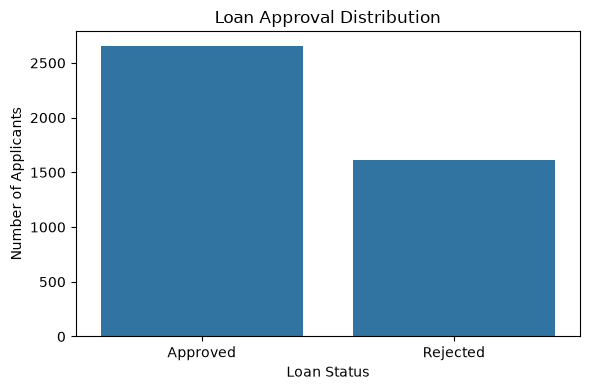

In [27]:
# ── Target distribution ───────────────────────────────────

target_counts = df_cleaned[TARGET].value_counts()
target_percent = df_cleaned[TARGET].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

display(target_summary)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_cleaned,
    x=TARGET
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

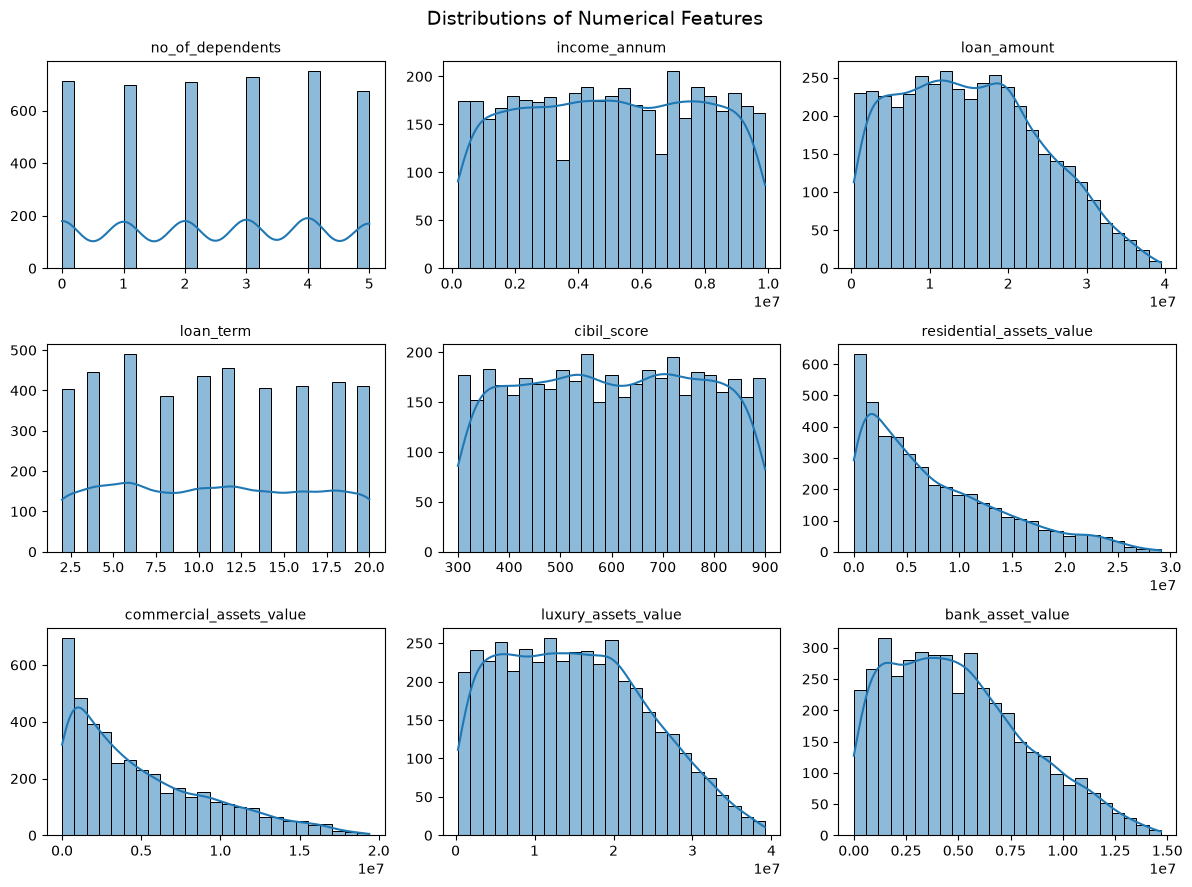

In [28]:
# ── Numerical feature distributions ────────────────────────

numeric_features = df_cleaned.select_dtypes(
    include=np.number
).columns.drop("loan_id")

fig, axes = plt.subplots(
    3, 3,
    figsize=(12, 9)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.histplot(
        data=df_cleaned,
        x=col,
        bins=25,
        kde=True,
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Hide unused axes if there are any
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Distributions of Numerical Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

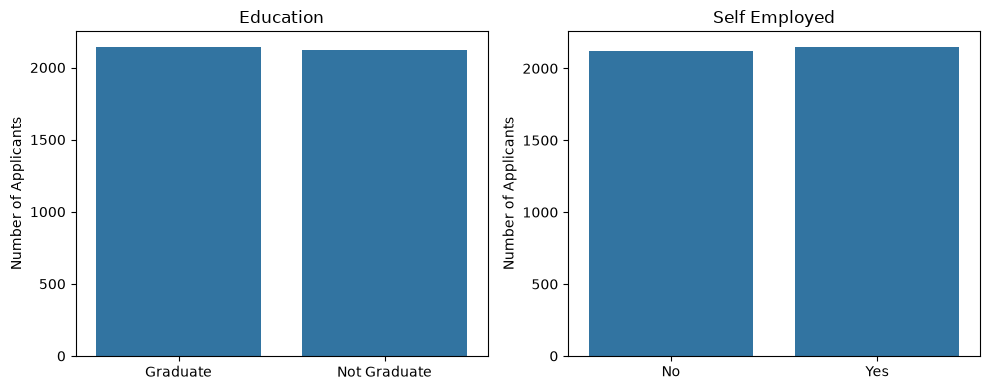

In [29]:
# ── Categorical feature distributions ──────────────────────

categorical_features = [
    "education",
    "self_employed"
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

for ax, col in zip(axes, categorical_features):
    sns.countplot(
        data=df_cleaned,
        x=col,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

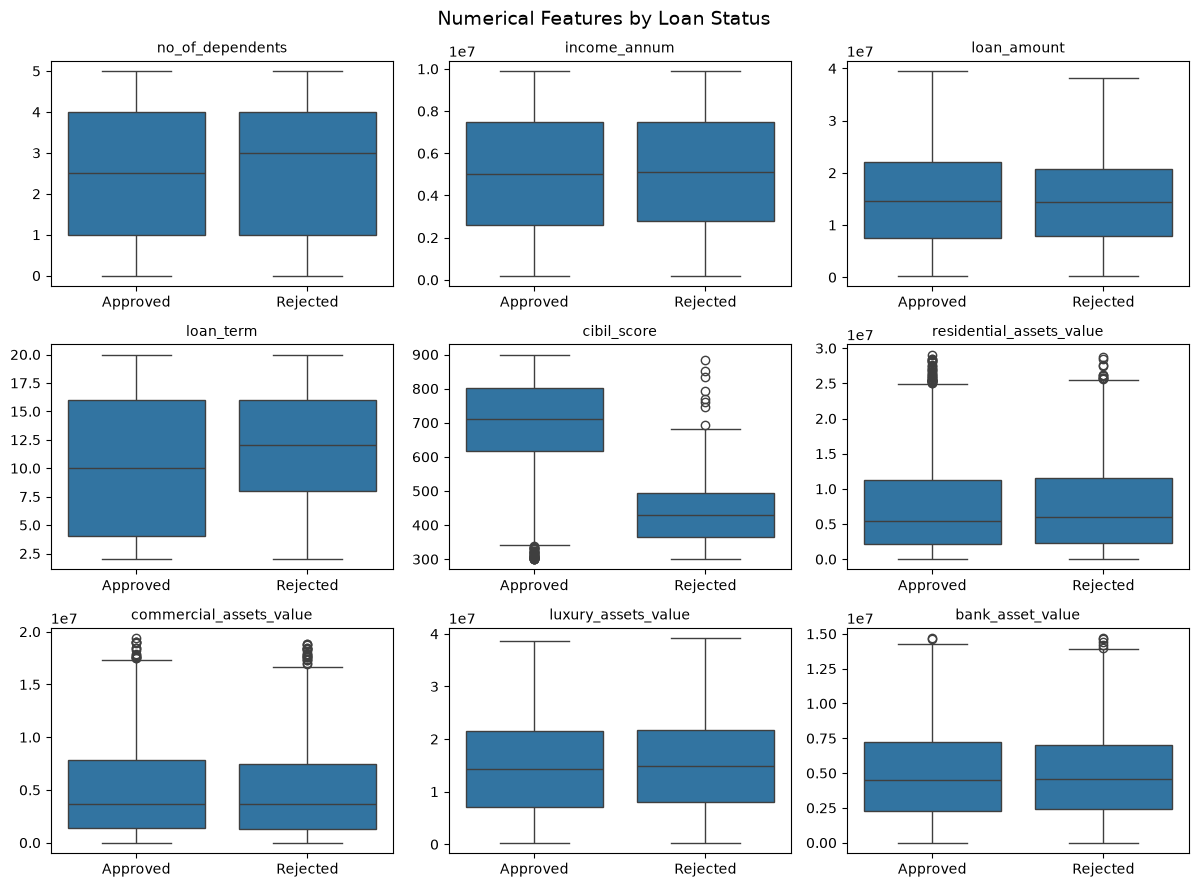

In [30]:
# ── Numerical features by loan status ──────────────────────

fig, axes = plt.subplots(
    3, 3,
    figsize=(12, 9)
)

axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.boxplot(
        data=df_cleaned,
        x=TARGET,
        y=col,
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Numerical Features by Loan Status",
    fontsize=14
)

plt.tight_layout()
plt.show()

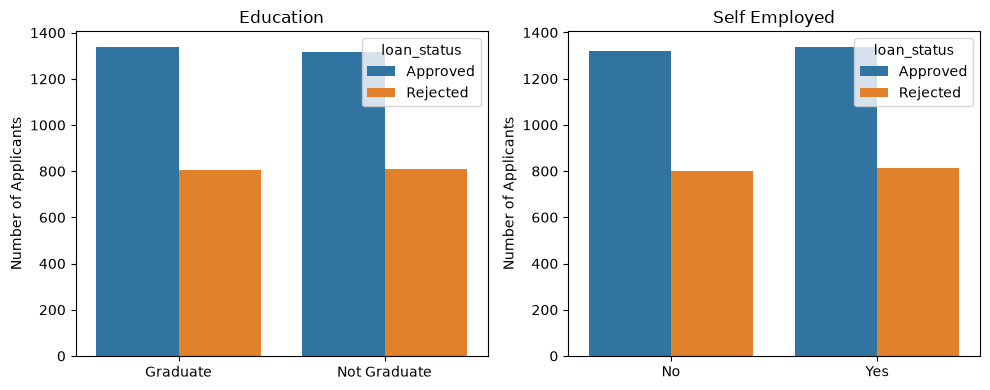

In [31]:
# ── Categorical features by loan status ────────────────────

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

for ax, col in zip(axes, categorical_features):
    sns.countplot(
        data=df_cleaned,
        x=col,
        hue=TARGET,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

### Outlier Analysis

we identify potential outliers for investigation rather than automatically removing them.

In [32]:
# ── IQR-based outlier summary ──────────────────────────────

outlier_summary = []

for col in numeric_features:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_cleaned[col] < lower_bound) |
        (df_cleaned[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Outliers": outliers,
        "Percentage": round(
            outliers / len(df_cleaned) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.sort_values(
        "Outliers",
        ascending=False
    )
)

,Feature,Outliers,Percentage
5,residential_assets_value,47,1.10
6,commercial_assets_value,37,0.87
8,bank_asset_value,5,0.12
0,no_of_dependents,0,0.00
1,income_annum,0,0.00
4,cibil_score,0,0.00
3,loan_term,0,0.00
2,loan_amount,0,0.00
7,luxury_assets_value,0,0.00


### Numerical Feature Correlations

We examine the relationships between numerical predictors using Spearman correlation.

This can reveal strongly related variables and possible redundancy between predictors.

Correlation does not imply causation, but it can help inform feature interpretation and model selection.

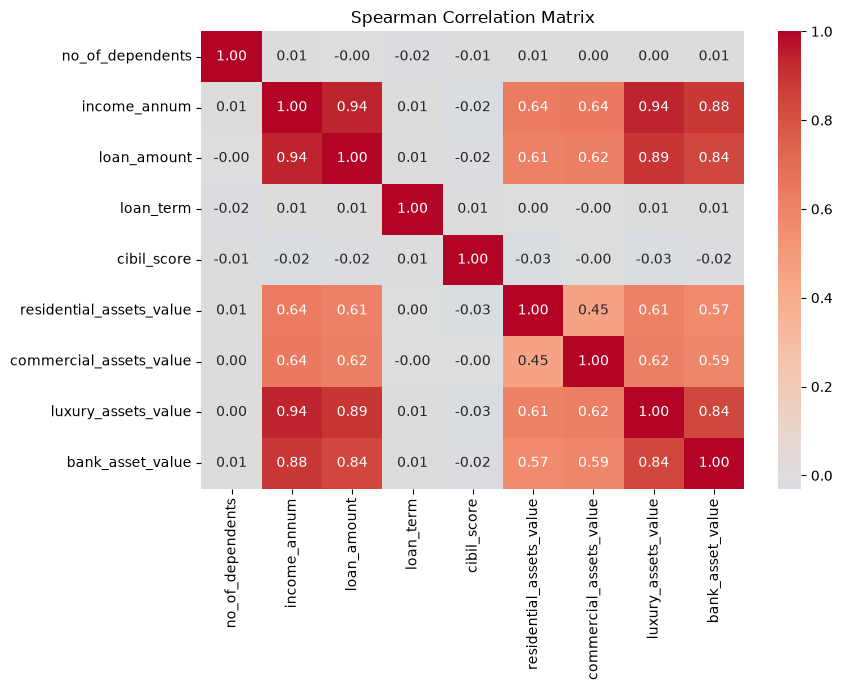

In [33]:
# ── Spearman correlation matrix ────────────────────────────

correlation_matrix = df_cleaned[
    numeric_features
].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Matrix")

plt.tight_layout()
plt.show()

### 4.8 EDA Findings

The exploratory analysis provides an overview of the applicant characteristics and their relationship with loan approval.

- The target variable contains two classes: `Approved` and `Rejected`.
- Numerical features show different ranges, distributions, and levels of variation across applicants.
- The boxplots show differences in several numerical features between approved and rejected applicants.
- The categorical features, `education` and `self_employed`, show the composition of applicants across their respective categories.
- Potential outliers were identified using the IQR method. These observations will not be removed automatically because extreme financial values may represent legitimate applicants.
- The correlation analysis shows relationships between several numerical predictors, which will be considered during model development.

Overall, the EDA provides an understanding of the main patterns and potential issues in the dataset. These findings will guide the preprocessing and modeling decisions in Step 5.

## Step 5: Data Preparation and Preprocessing

The exploratory analysis is complete, so the dataset is now prepared for machine learning.

The main goals of this step are to:

- Separate the predictors from the target variable.
- Exclude `loan_id`, since it is an identifier rather than a predictive feature.
- Split the data into training, validation, and test sets.
- Preserve the target-class proportions using stratified splitting.
- Build a preprocessing pipeline that handles missing values and categorical variables.
- Ensure that preprocessing is learned only from the training data to prevent data leakage.

The test set will remain untouched until the final evaluation in Step 9.

### 5.1 Define Features and Target

We separate the target variable, `loan_status`, from the predictor variables.

The `loan_id` column is also removed from the predictors because it uniquely identifies each application but does not represent an applicant characteristic.

The 28 invalid residential asset values were converted to missing values during cleaning. These values will be handled during preprocessing rather than manually calculated using the full dataset.

In [34]:
# ── Define features and target ─────────────────────────────

TARGET = "loan_status"

X = df_cleaned.drop(
    columns=[TARGET, "loan_id"]
)

y = df_cleaned[TARGET]

print(f"Features shape : {X.shape}")
print(f"Target shape   : {y.shape}")

print("\nTarget distribution:")
print(y.value_counts())

Features shape : (4269, 11)
Target shape   : (4269,)

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [35]:
# ── Encode target variable ─────────────────────────────────

target_mapping = {
    "Rejected": 0,
    "Approved": 1
}

y = y.map(target_mapping)

print("Encoded target values:")
print(y.value_counts().sort_index())

Encoded target values:
loan_status
0    1613
1    2656
Name: count, dtype: int64


### 5.3 Train, Validation and Test Split

The dataset is divided into three separate subsets:

- **Training set (70%)** — used to train the models.
- **Validation set (15%)** — used to compare models and make development decisions.
- **Test set (15%)** — kept untouched until final evaluation.

Stratification is used so that the proportion of approved and rejected loans remains similar across all three datasets.

The test set will not be used during preprocessing, model selection, or hyperparameter tuning.

In [36]:
from sklearn.model_selection import train_test_split

# ── First split: training vs temporary set ─────────────────

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# ── Second split: validation vs test ──────────────────────

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Dataset sizes")
print("-" * 35)

print(f"Training   : {len(X_train):,}")
print(f"Validation : {len(X_val):,}")
print(f"Test       : {len(X_test):,}")

ImportError: DLL load failed while importing _base: An Application Control policy has blocked this file.